# Notebook 02 — Training runs

**Project:** deepbook-flowcast — predicting short-term price moves on DeepBook, Sui's on-chain order book.

This notebook tells the story of the **training runs**: what each run tried, what it found, and what we changed next.
Training itself ran in the terminal; every run saved its settings and scores in `runs/<time>_<model>/`, which this
notebook reads. The side-by-side model comparison (confusion matrices, SHAP, costs) is in notebook 03.

**How every run trains a model** (one per pool × horizon × feature set):
1. **Tune** the settings with `TimeSeriesSplit(3)` **inside August** (train on earlier weeks, score on the next week).
2. **Refit** the winning setting on all of August (Aug 2–31; Aug 1 is the warm-up day).
3. **Score** it once on **September** (macro F1), next to the best rule. October and 2026 are never touched.

| Run | Command | Commit |
|---|---|---|
| Logistic regression, run 1 | `uv run flowcast train logreg` | ≈ `d52a73a` (before run folders existed) |
| Logistic regression, run 2 | `uv run flowcast train logreg` | ≈ `d52a73a` |
| LightGBM | `uv run flowcast train lgbm` | `a36386a` (clean) |

## 1. Imports and the list of runs

In [1]:
# Import libraries
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from flowcast.config import RUNS

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", None)
plt.rcParams["figure.dpi"] = 110

In [2]:
# Every training run: when, which model, which code, what was tried
runs = []
for d in sorted(RUNS.glob("*_logreg")) + sorted(RUNS.glob("*_lgbm")):
    c = json.loads((d / "config.json").read_text())
    runs.append({"run": d.name, "model": c["kind"], "commit": c.get("git", {}).get("commit", ""),
                 "grid": json.dumps(c["grid"]), "fixed": json.dumps(c.get("fixed", {}))})
pd.DataFrame(runs)

,run,model,commit,grid,fixed
0,20261009-180800_logreg,logreg,d52a73a (approx.),"{""model__C"": [0.01, 0.1, 1.0]}","{""class_weight"": ""balanced""}"
1,20261009-182404_logreg,logreg,d52a73a (approx.),"{""model__C"": [0.0001, 0.001, 0.01, 0.1], ""model__class_weight"": [""balanced"", null]}",{}
2,20261009-191600_lgbm,lgbm,a36386add7de36c110d15c000eb275221ba27bf1,"{""model__n_estimators"": [150, 400], ""model__num_leaves"": [15, 63], ""model__class_weight"": [""balanced"", null]}",{}


In [3]:
# Helper: one run's results, each pool's own model only (no carry-over rows)
def results(run):
    r = pd.read_csv(RUNS / run / "results.csv")
    r = r[r.trained_on == r.pool].copy()
    r["horizon"] = pd.Categorical(r.horizon, ["1s", "10s", "60s"], ordered=True)
    r["pool"] = pd.Categorical(r.pool, ["SUI_USDC", "DEEP_USDC"], ordered=True)
    return r.set_index(["pool", "horizon", "features"]).sort_index()

R1, R2, LGB = "20261009-180800_logreg", "20261009-182404_logreg", "20261009-191600_lgbm"

## 2. Logistic regression, run 1

**Tried:** `C` ∈ {0.01, 0.1, 1} (how cautious the model is: small = only trusts strong patterns),
class weights fixed to `balanced` (mistakes on rare classes cost more).

In [4]:
r1 = results(R1)
r1[["C", "train_f1", "sep_f1", "best_rule_f1"]].assign(lift=r1.sep_f1 - r1.best_rule_f1).round(3)

C  train_f1  sep_f1  best_rule_f1   lift
pool      horizon features                                             
SUI_USDC  1s      all       0.01     0.495   0.450         0.361  0.089
                  deepbook  0.01     0.483   0.437         0.361  0.076
          10s     all       0.01     0.444   0.450         0.357  0.092
                  deepbook  0.01     0.439   0.444         0.357  0.087
          60s     all       0.01     0.399   0.398         0.359  0.038
                  deepbook  0.01     0.394   0.392         0.359  0.033
DEEP_USDC 1s      all       0.01     0.434   0.398         0.424 -0.026
                  deepbook  0.01     0.425   0.381         0.424 -0.043
          10s     all       0.01     0.499   0.447         0.396  0.051
                  deepbook  0.01     0.469   0.416         0.396  0.020
          60s     all       0.01     0.499   0.445         0.393  0.052
                  deepbook  0.01     0.467   0.415         0.393  0.022

**What we saw:**
- Beats the best rule on SUI_USDC by about +0.09 at 1 s and 10 s.
- `C = 0.01` won **every time**, which is the **edge of the grid**: an even smaller C might be better, so the tuning
  wasn't finished.
- DEEP_USDC at 1 s **loses to the rule**. Guess: `class_weight="balanced"` makes the model call UP/DOWN too often in a
  market that is 85% flat.

**Decision:** widen the grid to smaller C and let tuning choose the class weights too.

## 3. Logistic regression, run 2

**Tried:** `C` ∈ {0.0001, 0.001, 0.01, 0.1} × `class_weight` ∈ {balanced, none} = 8 settings × 3 folds per model.
This run also records `cv_f1`: the tuning score on August, to compare with September.

In [5]:
r2 = results(R2)
r2[["C", "class_weight", "cv_f1", "train_f1", "sep_f1", "best_rule_f1"]].round(4)

C class_weight   cv_f1  train_f1  sep_f1  \
pool      horizon features                                                  
SUI_USDC  1s      all       0.0001     balanced  0.4852    0.4954  0.4525   
                  deepbook  0.0001     balanced  0.4787    0.4828  0.4394   
          10s     all       0.0010          NaN  0.4366    0.4430  0.4486   
                  deepbook  0.0001          NaN  0.4349    0.4364  0.4418   
          60s     all       0.0010          NaN  0.3855    0.3989  0.4006   
                  deepbook  0.0010          NaN  0.3787    0.3935  0.3957   
DEEP_USDC 1s      all       0.0001     balanced  0.4390    0.4384  0.4034   
                  deepbook  0.0001     balanced  0.4202    0.4282  0.3855   
          10s     all       0.0001     balanced  0.4505    0.4988  0.4482   
                  deepbook  0.0001     balanced  0.4105    0.4678  0.4157   
          60s     all       0.0100          NaN  0.4396    0.4993  0.4453   
                  deepbook  0.0100          NaN  0.4020    0.4667  0.4162   

                            best_rule_f1  
pool      horizon features                
SUI_USDC  1s      all             0.3612  
                  deepbook        0.3612  
          10s     all             0.3575  
                  deepbook        0.3575  
          60s     all             0.3594  
                  deepbook        0.3594  
DEEP_USDC 1s      all             0.4240  
                  deepbook        0.4240  
          10s     all             0.3956  
                  deepbook        0.3956  
          60s     all             0.3933  
                  deepbook        0.3933

In [6]:
# Run 1 vs run 2: did the wider tuning change anything?
cmp = pd.DataFrame({"run 1 C": r1.C, "run 2 C": r2.C, "run 2 class_weight": r2.class_weight.fillna("none"),
                    "run 1 Sep F1": r1.sep_f1, "run 2 Sep F1": r2.sep_f1})
cmp["change"] = cmp["run 2 Sep F1"] - cmp["run 1 Sep F1"]
cmp.round(4)

run 1 C  run 2 C run 2 class_weight  run 1 Sep F1  \
pool      horizon features                                                      
SUI_USDC  1s      all          0.01   0.0001           balanced        0.4502   
                  deepbook     0.01   0.0001           balanced        0.4373   
          10s     all          0.01   0.0010               none        0.4498   
                  deepbook     0.01   0.0001               none        0.4442   
          60s     all          0.01   0.0010               none        0.3976   
                  deepbook     0.01   0.0010               none        0.3922   
DEEP_USDC 1s      all          0.01   0.0001           balanced        0.3982   
                  deepbook     0.01   0.0001           balanced        0.3815   
          10s     all          0.01   0.0001           balanced        0.4467   
                  deepbook     0.01   0.0001           balanced        0.4158   
          60s     all          0.01   0.0100               none        0.4454   
                  deepbook     0.01   0.0100               none        0.4150   

                            run 2 Sep F1  change  
pool      horizon features                        
SUI_USDC  1s      all             0.4525  0.0023  
                  deepbook        0.4394  0.0021  
          10s     all             0.4486 -0.0012  
                  deepbook        0.4418 -0.0024  
          60s     all             0.4006  0.0030  
                  deepbook        0.3957  0.0035  
DEEP_USDC 1s      all             0.4034  0.0052  
                  deepbook        0.3855  0.0040  
          10s     all             0.4482  0.0015  
                  deepbook        0.4157 -0.0000  
          60s     all             0.4453 -0.0001  
                  deepbook        0.4162  0.0012

**What we saw:**
- Scores moved by at most **±0.005** although C changed up to 100×: logistic regression has hit its **ceiling**; more
  tuning won't help. (0.0001 sits at the edge again, but the scores are flat there.)
- Tuning on August still chose `balanced` for DEEP 1 s, and it still loses to the rule: the class-weight guess was
  **wrong**. A weighted sum can't express "only act when imbalance is extreme".
- `cv_f1` (August) is close to September: the fold setup is a fair preview, and there's no sign of overfitting.

**Decision:** stop tuning logistic regression; try a model that can learn thresholds — gradient boosting.

## 4. LightGBM

**Tried:** number of trees ∈ {150, 400} × leaves per tree ∈ {15, 63} × class weights ∈ {balanced, none},
learning rate 0.05, at least 200 rows per leaf, 80% row/column subsampling. No log/clip/scale (trees only compare values)
and missing values handled natively. The run took **~85 minutes** (≈ 80 of them in the 1 s and DEEP 10 s models).

In [7]:
lg = results(LGB)
out = lg[["n_estimators", "num_leaves", "class_weight", "cv_f1", "train_f1", "sep_f1", "best_rule_f1", "fit_s"]].copy()
out["logreg_sep_f1"] = r2.sep_f1
out["overfit (train - Sep)"] = lg.train_f1 - lg.sep_f1
out.round(3)

n_estimators  num_leaves class_weight  cv_f1  \
pool      horizon features                                                 
SUI_USDC  1s      all                400          63     balanced  0.516   
                  deepbook           400          63     balanced  0.505   
          10s     all                150          15          NaN  0.448   
                  deepbook           150          15          NaN  0.444   
          60s     all                150          15          NaN  0.390   
                  deepbook           150          15          NaN  0.384   
DEEP_USDC 1s      all                400          63          NaN  0.521   
                  deepbook           400          63          NaN  0.498   
          10s     all                400          63          NaN  0.502   
                  deepbook           400          63          NaN  0.473   
          60s     all                150          15          NaN  0.438   
                  deepbook           150          15          NaN  0.415   

                            train_f1  sep_f1  best_rule_f1  fit_s  \
pool      horizon features                                          
SUI_USDC  1s      all          0.585   0.479         0.361  763.0   
                  deepbook     0.575   0.465         0.361  807.0   
          10s     all          0.467   0.463         0.357  224.0   
                  deepbook     0.462   0.458         0.357  210.0   
          60s     all          0.476   0.404         0.359   95.0   
                  deepbook     0.474   0.398         0.359   91.0   
DEEP_USDC 1s      all          0.620   0.502         0.424  704.0   
                  deepbook     0.599   0.482         0.424  656.0   
          10s     all          0.608   0.486         0.396  563.0   
                  deepbook     0.588   0.463         0.396  554.0   
          60s     all          0.553   0.463         0.393   97.0   
                  deepbook     0.542   0.445         0.393   98.0   

                            logreg_sep_f1  overfit (train - Sep)  
pool      horizon features                                        
SUI_USDC  1s      all               0.452                  0.106  
                  deepbook          0.439                  0.109  
          10s     all               0.449                  0.004  
                  deepbook          0.442                  0.004  
          60s     all               0.401                  0.073  
                  deepbook          0.396                  0.077  
DEEP_USDC 1s      all               0.403                  0.118  
                  deepbook          0.385                  0.117  
          10s     all               0.448                  0.122  
                  deepbook          0.416                  0.125  
          60s     all               0.445                  0.090  
                  deepbook          0.416                  0.096

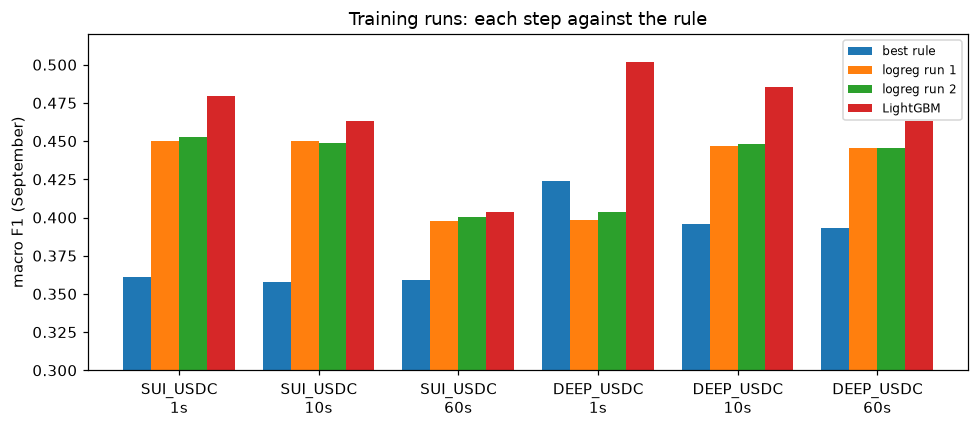

In [8]:
# Sep macro F1 per run, + Binance features ("all"), against the best rule
plot = pd.DataFrame({"best rule": lg.best_rule_f1, "logreg run 1": r1.sep_f1, "logreg run 2": r2.sep_f1,
                     "LightGBM": lg.sep_f1}).xs("all", level="features")
ax = plot.plot.bar(figsize=(9, 4), width=0.8)
ax.set_ylim(0.3, 0.52); ax.set_ylabel("macro F1 (September)"); ax.set_xlabel("")
ax.set_xticklabels([f"{p}\n{h}" for p, h in plot.index], rotation=0); ax.legend(fontsize=8)
ax.set_title("Training runs: each step against the rule")
plt.tight_layout(); plt.show()

**What we saw:**
- LightGBM beats logistic regression **everywhere**, most at short horizons (SUI: +0.027 at 1 s, +0.003 at 60 s).
- It **fixes DEEP 1 s** (0.502 vs the rule's 0.424): thresholds were the problem (notebook 03 shows the `imb_1`
  "staircase" in the SHAP plots).
- Train is ~0.11 above September for the big models (some memorising), but `cv_f1` predicted September well, and
  September is what counts.
- **Grid edges again:** the biggest setting (400 trees, 63 leaves) won at 1 s and DEEP 10 s; the smallest (150, 15) at
  SUI 10 s / 60 s.

**Decision:** keep LightGBM as the main model; next time use **early stopping** (add trees until the held-out fold
stops improving) instead of a fixed tree count — faster and finds the size automatically.

## 5. Summary

| Run | Tried | Best Sep F1 (SUI 1s / 10s / 60s, + Binance) | Lesson |
|---|---|---|---|
| logreg 1 | C ∈ {0.01, 0.1, 1}, balanced | 0.450 / 0.450 / 0.398 | beats the rules; C at the grid edge; DEEP 1 s loses |
| logreg 2 | C ∈ {1e-4 … 0.1} × class weights | 0.452 / 0.449 / 0.401 | flat across C: linear ceiling; class weights weren't the DEEP issue |
| LightGBM | trees × leaves × class weights | 0.479 / 0.463 / 0.404 | thresholds matter; fixes DEEP 1 s; grid edges → early stopping |

Every lift above was later confirmed with day-level bootstrap intervals (notebook 04). From here on, each run also
saves `cv_results.csv` (every setting's score on each August fold), so future runs can plot score vs setting.